# 1. Sea $X$ una variable aleatoria exponencial de parámetro $\lambda$ y $g(x) = \mathbb{I}(x \geq \tau)$ para alguna $\tau > 0$. Supongamos que se desea calcular

# $$\theta = \mathbb{E}(g(X)) = \int_{\tau}^{\infty} \lambda \exp(-\lambda x)\,dx$$

## (a) Para $\lambda = 1$ y $\tau = 4$, construye el estimador de Monte Carlo clásico. Genera 500 muestras de tamaño 1000 y estudia la distribución empírica de los estimadores obtenidos. Compara su media y varianza empíricas con los valores teóricos.

Tenemos que 

$$\theta = \int_0^{\infty}  \mathbb{I}(x \geq \tau) \lambda \exp(-\lambda x)\,dx$$

Con lo cual tenemos que si $X_1, ..., X_n \sim \mathcal{Exp}(\lambda)$, entonces 

$$\frac{1}{n} \sum\limits_{i = 1}^n \mathbb{I}(X_i \geq \tau) \to \theta.$$

El resultado se esperaría que estuviera cerca de $\int_4^{\infty} e^{-x}dx = e^-4$, ahora calculemos la media,

$$\mathbb{E}[\hat{\theta}] = \mathbb{E}[\frac{1}{n} \sum\limits_{i = 1}^n \mathbb{I}(X_i \geq \tau)] = \frac{1}{n} \sum\limits_{i = 1}^n \mathbb{E}[\mathbb{I}(X_i \geq \tau)] = \frac{n}{n}\mathbb{E}[\mathbb{I}(X_i \geq \tau)] = \theta.$$

Y la varianza, tendremos que será,

$$\mathbb{Var}(\hat{\theta}) = \mathbb{Var}[\frac{1}{n} \sum\limits_{i = 1}^n \mathbb{I}(X_i \geq \tau)] = \frac{1}{n^2} \sum\limits_{i = 1}^n \mathbb{Var}[\mathbb{I}(X_i \geq \tau)] = \frac{1}{n}\mathbb{Var}[\mathbb{I}(X_i \geq \tau)] = \frac{\theta(1 - \theta)}{n}$$

In [34]:
import numpy as np
import matplotlib.pyplot as plt

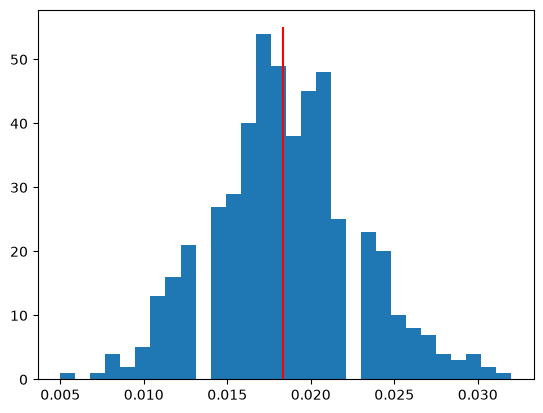

In [35]:
def metodo_general_exp(n, lam, tau, seed = None):
    if seed != None:
        np.random.seed(seed)
    X = np.random.exponential(1/lam, n)
    theta = np.mean(X >= tau)
    return theta

np.random.seed(29)
m = 500
n = 1000
Theta = np.zeros(m)
for i in range(m):
    Theta[i] = metodo_general_exp(n, 1, 4)

plt.hist(Theta, bins = 30)
plt.vlines(np.exp(-4), ymin=0, ymax =55, colors = "red")
plt.show()

In [36]:
media_emp = np.mean(Theta)
var_emp = np.var(Theta)

media_teo = np.exp(-4)
var_teo = media_teo * (1-media_teo)/n

print(f"Medias: empirica = {media_emp} y teorica = {media_teo}")
print(f"Varianzas: empirica = {var_emp} y teorica = {var_teo}")

Medias: empirica = 0.018444000000000002 y teorica = 0.01831563888873418
Varianzas: empirica = 1.9010864e-05 y teorica = 1.7980176260831665e-05


## (b) Calcula la transformada de Esscher de la distribución exponencial y utilízala como distribución instrumental para construir un estimador mediante muestreo por importancia. Selecciona el parámetro de la transformada de manera que la esperanza bajo la nueva distribución sea igual a $\tau$. Compara la variabilidad del nuevo estimador con la del estimador clásico.

La transformación de Esscher esta dada por $f_t(x) = \frac{e^{tx}f(x)}{m_X(t)}$, con $f(x) = \lambda e^{-\lambda x}$ y $m_X(t) = \frac{\lambda}{\lambda - t}$, así tendremos que 

$$f_t(x) = \frac{e^{tx}\lambda e^{-\lambda x}}{\frac{\lambda}{\lambda - t}} = (\lambda - t)e^{x(t-\lambda)} = (\lambda - t)e^{-x(\lambda - t)} \sim \mathcal{Exp}(\lambda -t)$$

de esta manera, tendremos que $\mathbb{E}[f_t(x)] = \frac{1}{\lambda - t} = \tau$ y así

$$\frac{1}{\tau} = \lambda - t \quad \rightarrow \quad t = \lambda - \frac{1}{\tau}.$$

Con lo cual nuestra distribucion instrumental será $f_t(x) \sim \mathcal{Exp}(\lambda - (\lambda - \frac{1}{\tau})) = \mathcal{Exp}(\frac{1}{\tau})$ y así 

$$\theta = \int_0^{\infty} \mathbb{I}(x \geq \tau) \frac{\lambda \tau \exp(-\lambda x)}{\exp(-\frac{1}{\tau} x)} f_t(x)\,dx = \int_0^{\infty} \mathbb{I}(x \geq \tau) \lambda \tau \exp(-(\lambda - \frac{1}{\tau}) x) f_t(x)\,dx,$$

y así para $\hat{\theta}$ simulamos $X_1, ..., X_n \sim \mathcal{Exp}(\frac{1}{\tau})$ y así

$$\hat{\theta} = \sum\limits_{i=1}^{n} \mathbb{I}(X_i \geq \tau) \lambda \tau \exp \{-(\lambda - \frac{1}{\tau})\,X_i\}.$$

Finalmente la varianza estará dada por 

$$\mathbb{Var}(\hat{\theta}) = \frac{1}{n} \int_0^\infty (h(x) - \theta)^2 f_t(x)\,dx = \frac{1}{n} [\int_0^\infty h^2(x) f_t(x)\,dx -2\theta \int_0^\infty h(x)f_t(x)\,dx + \theta^2 \int_0^\infty f_t(x)\,dx]$$
$$ = \frac{1}{n} [\int_0^\infty h^2(x) f_t(x)\,dx -2\theta^2 + \theta^2] = \frac{1}{n} [\int_0^\infty h^2(x)f_t(x)\,dx -\theta^2],$$

ahora calculemos, 

$$\int_0^\infty h^2(x)f_t(x)\,dx = \int_0^\infty (\mathbb{I}(x \geq \tau) \lambda \tau \exp\{-(\lambda - \frac{1}{\tau})x\})^2 f_t(x)\,dx = \int_0^\infty \mathbb{I}^2(x \geq \tau) \lambda^2 \tau^2 \exp\{-2(\lambda - \frac{1}{\tau})x\} f_t(x) \, dx$$
$$ = \int_{\tau}^\infty \lambda^2 \tau^2 \exp\{-2(\lambda - \frac{1}{\tau})\}) f_t(x)\,dx = \int_{\tau}^\infty \lambda^2 \tau^2 \exp\{-2(\lambda - \frac{1}{\tau})x\} \frac{1}{\tau}\exp \{-\frac{1}{\tau} x\} = \tau \lambda^2 \int_{\tau}^\infty \exp\{-(2\lambda - \frac{1}{\tau})x\}$$
$$= -\tau \lambda^2 \left[\frac{e^{-(2\lambda -\frac{1}{\tau})x}}{2\lambda -\frac{1}{\tau}}\right]_{\tau}^{\infty} = \tau \lambda^2 \left[\frac{e^{-(2\lambda -\frac{1}{\tau})\tau}}{2\lambda -\frac{1}{\tau}}\right] = \tau \lambda^2 \left[\frac{e^{1-2\lambda \tau}}{2\lambda -\frac{1}{\tau}}\right]$$

juntando todo tenemos, y usando el valor de theta teorico $\theta = e^{-\lambda\tau}$

$$\mathbb{Var}(\hat{\theta}) = \frac{1}{n} \left[\tau \lambda^2 \left[\frac{e^{1-2\lambda \tau}}{2\lambda -\frac{1}{\tau}}\right] -\theta^2\right] \approx \frac{1}{n} \left[\tau \lambda^2 \left[\frac{e^{1-2\lambda \tau}}{2\lambda -\frac{1}{\tau}}\right] - e^{-2\lambda\tau} \right].$$

Sustituyendo obtenemos

$$\mathbb{Var}(\hat{\theta}) = \frac{1}{1000} \left[\frac{4e^{-7}}{7} - e^{-8}\right] = \frac{.000521 - .000335}{1000} = \frac{.000186}{1000} = 1.86 \times 10^{-7}$$

In [37]:
def Trans_Esscher_exp(n, lam, tau, seed = None):
    if seed != None:
        np.random.seed(seed)
    X = np.random.exponential(tau, n)
    sum = np.where(X >= tau, lam * tau * np.exp(-(lam - 1/tau) * X), 0)
    theta = np.mean(sum)
    return theta

In [38]:
np.random.seed(29)
theta = Trans_Esscher_exp(1000, 1, 4)
theta

np.float64(0.019231533859656418)

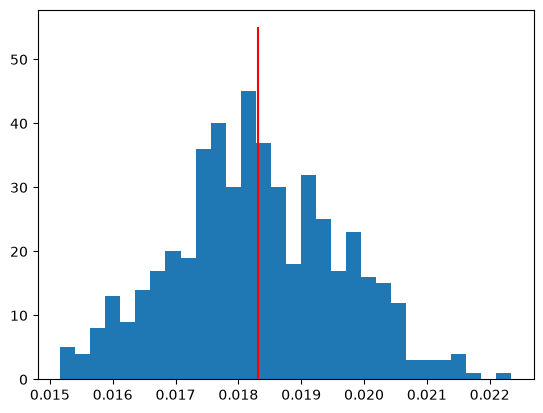

In [39]:
Theta_esscher = np.zeros(m)
for i in range(m):
    Theta_esscher[i] = Trans_Esscher_exp(n, 1, 4, seed = 29 + i)

plt.hist(Theta_esscher, bins = 30)
plt.vlines(np.exp(-4), 0, 55, colors="red")
plt.show()

In [40]:
media_emp_esscher = np.mean(Theta_esscher)
var_emp_esscher = np.var(Theta_esscher)

var_teo_esscher = ((4*np.exp(-7)/7)-np.exp(-8))/n

print(f"Medias: teorica = {media_teo}, empirica con metodo general = {media_emp} y con Esscher = {media_emp_esscher}")
print(f"Medias: teorica general = {var_teo}, empirica general = {var_emp}, teorica Esscher = {var_teo_esscher} y empirica Esscher = {var_emp_esscher}")

Medias: teorica = 0.01831563888873418, empirica con metodo general = 0.018444000000000002 y con Esscher = 0.018287498381138485
Medias: teorica general = 1.7980176260831665e-05, empirica general = 1.9010864e-05, teorica Esscher = 1.856127809857832e-07 y empirica Esscher = 1.7407428785234592e-06


# 2. Sean $U$ y $W$ dos variables aleatorias independientes con distribución uniforme en el intervalo $(0,1)$. Se desea estimar

$$\theta = \mathbb{E}\left[e^{(U+W)^2}\right].$$

## (a) Construye el estimador de Monte Carlo clásico y estudia su variabilidad mediante 500 muestras de tamaño 1000.

Comenzamos simulando 2 variables aleatorias uniformes $U_1, ..., U_n, W_1, ..., W_n \sim \mathcal{U}(0, 1)$ Así, el estimador de Monte Carlo clasico será,

$$\hat{\theta} = \frac{1}{n} \sum\limits_{i=1}^n e^{(U_i + W_i)^2}$$

In [41]:
def MC_Unif(n, seed = None):
    if seed != None:
        np.random.seed(seed)
    U = np.random.uniform(0, 1, n)
    W = np.random.uniform(0, 1, n)
    theta = np.mean(np.exp((U + W)**2))
    return theta

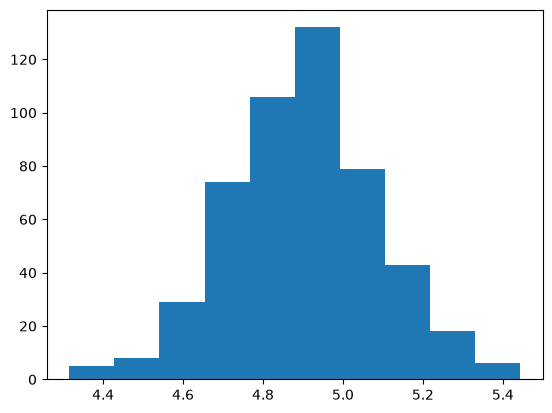

In [42]:
np.random.seed(29)
Theta_uni = np.zeros(m)
for i in range(m):
    Theta_uni[i] = MC_Unif(n)

plt.hist(Theta_uni, bins = 10)
plt.show()

In [43]:
var_uni = np.var(Theta_uni)

print(f"Var = {var_uni}")

Var = 0.03396849449026766


## (b) Utiliza el método de variables de control considerando $Z = (U+W)^2$. Calcula $\mathbb{E}[Z]$ y estima el coeficiente óptimo de la variable de control utilizando las covarianzas y varianzas muestrales. Compara la variabilidad del nuevo estimador con la del estimador clásico.

Primero calculemos,

$$\mathbb{E}[Z] = \mathbb{E}[(U+W)^2] = \mathbb{E}[U^2 +2UW + W^2] = \mathbb{E}[U^2] +2\mathbb{E}[UW] +\mathbb{E}[W^2] = 2\mathbb{E}[U^2] +2\mathbb{E}[UW].$$

Por un lado tendremos que

$$\mathbb{E}[U^2] = \mathbb{Var}(U) + \mathbb{E}^2[U] = \frac{1}{12} + \frac{1}{4} = \frac{1}{3},$$

y luego como U y W son independientes, entonces

$$\mathbb{E}[UW] = \mathbb{E}[U]\mathbb{E}[W] = \frac{1}{4}.$$

Con lo cual tendremos

$$\mathbb{E}[Z] = 2\frac{1}{3} + 2\frac{1}{4} = \frac{4 + 3}{6} = \frac{7}{6}.$$

Ahora estimemos el coeficiente optimo, el cual será

$$c = \frac{\text{Cov}(g(X), Z)}{\mathbb{Var}(Z)} = \frac{\text{Cov}(e^{(U+W)^2}, (U+W)^2)}{\mathbb{Var}((U+W)^2)}$$

In [44]:
def VC_unif(n, seed = None):
    if seed != None:
        np.random.seed(seed)
    U = np.random.uniform(0, 1, n)
    W = np.random.uniform(0, 1, n)
    Z = (U + W)**2
    EZ = 7/6
    gX = np.exp((U+W)**2)
    c = np.cov(gX, Z)[0,1]/np.var(Z)
    theta = np.mean(gX - c*(Z - EZ))
    return theta

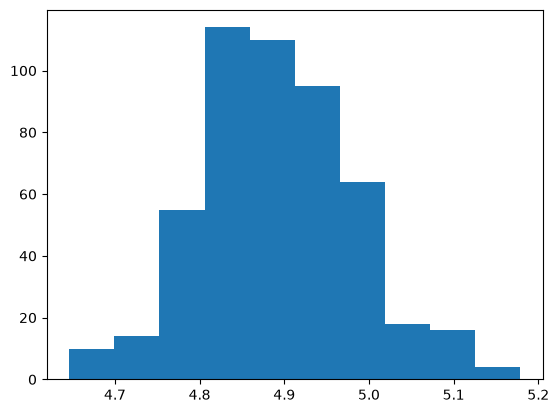

In [45]:
np.random.seed(29)
Theta_VC = np.zeros(m)
for i in range(m):
    Theta_VC[i] = VC_unif(n)

plt.hist(Theta_VC, bins = 10)
plt.show()


In [46]:
var_VC = np.var(Theta_VC)
print(f"Var = {var_VC}")

Var = 0.008263280570348084


# 3. Considera que se desea calcular

# $$\theta = \int_0^1 \sqrt{1+x^2}\,dx$$

## (a) Construye el estimador de Monte Carlo clásico y estudia su variabilidad mediante 500 muestras de tamaño 1000.

Necistamos $X_1, .., X_n \sim \mathcal{U}(0, 1)$, y así

$$\hat{\theta} = \frac{1}{n}\sum\limits_{i=1}^n \sqrt{1+X_i^2}$$

Y su varianza será,

$$\mathbb{Var}(\hat{\theta}) = \mathbb{Var}(\frac{1}{n}\sum\limits_{i=1}^n \sqrt{1+X_i^2}) = \frac{1}{n^2} \mathbb{Var}(\sum\limits_{i=1}^n \sqrt{1+X_i^2}) = \frac{1}{n^2} \sum\limits_{i=1}^n \mathbb{Var}(\sqrt{1+X_i^2}) = \frac{1}{n} \mathbb{Var}(\sqrt{1+X_i^2}),$$

pero el valor de la integral nos da, por sustitucion trigonometrica,

$$\mathbb{Var}(\sqrt{1+X_i^2}) = \mathbb{E}[1+X_i^2] - \mathbb{E}^2[\sqrt{1+X_i^2}] = 1 + \mathbb{E}[X_i^2] - \theta^2$$
$$ = 1 + \mathbb{Var}[X_i] + \mathbb{E}^2[X_i] - \theta^2 = 1 + \frac{1}{12} + \frac{1}{4} - (\frac{1}{2}\left[\sqrt{2} + \ln(1+\sqrt{2})\right])^2 = \frac{16}{12} - \frac{1}{4}\left[\sqrt{2} + \ln(1+\sqrt{2})\right]^2 = \frac{16}{12} - \frac{1}{4}\left[2 + 2\sqrt{2}\ln(1+\sqrt{2}) + \ln(1+\sqrt{2})^2 \right].$$

Finalemente tendremos que 

$$\mathbb{Var}(\theta) = \frac{1}{1000} (\frac{16}{12} - \frac{1}{4}\left[2 + 2\sqrt{2}\ln(1+\sqrt{2}) + \ln(1+\sqrt{2})^2 \right])$$

In [47]:
def MC_unif_3(n, seed = None):
    if seed != None:
        np.random.seed(seed)
    X = np.random.uniform(0, 1, n)
    theta = np.mean(np.sqrt(1+ X**2))
    return theta
    

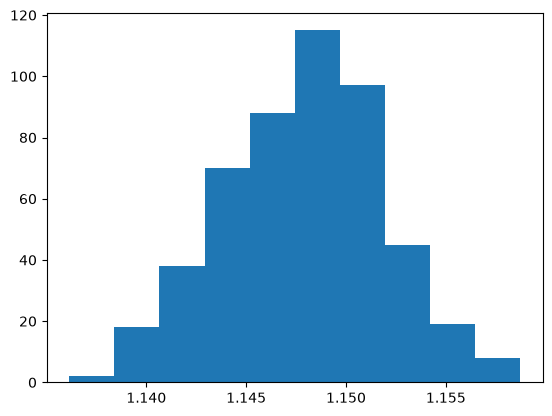

In [48]:
np.random.seed(29)
Theta_3 = np.zeros(m)
for i in range(m):
    Theta_3[i] = MC_unif_3(n)

plt.hist(Theta_3)
plt.show()

In [49]:
var_teo_3 = (16/12 - (1/4) * (2 + 2*np.sqrt(2)*np.log(1 + np.sqrt(2)) + np.log(1 + np.sqrt(2))**2))/1000
var_empirico = np.var(Theta_3)

media_emp_3 = np.mean(Theta_3)

print(f"Varianza teorica = {var_teo_3} y Varainza empírica = {var_empirico}")
print(f"Meida = {media_emp_3}")

Varianza teorica = 1.59032432191788e-05 y Varainza empírica = 1.6000207953852027e-05
Meida = 1.1478956506329259


## (b) Utiliza el método de variables antitéticas para obtener un estimador de menor varianza. Compara su variabilidad con la del estimador clásico, manteniendo el mismo número total de evaluaciones de la función en ambos métodos.

Sean $X_1, ..., X_n \sim \mathcal{U}(0, 1)$, entonces definimos

$$U_1 = (X_1, ..., X_n) \qquad U_2 = (1 - X_1, ..., 1 - X_n)$$

Así entonces obtendremos 

$$\hat{\theta}_{VA} = \frac{1}{n} \sum\limits_{i=1}^{n} \frac{\sqrt{1 + X_i^2} + \sqrt{1 + (1 - X_i)^2}}{2} = \frac{1}{n} \sum\limits_{i=1}^{n} \frac{\sqrt{1 + X_i^2} + \sqrt{2 - 2X_i +X_i^2}}{2}.$$

Y su varianza será

$$\mathbb{Var}(\hat{\theta}_{VC}) = \frac{1}{n} \cdot \frac{1}{4}\left(\mathbb{Var}(\sqrt{1 + X_i^2}) + \mathbb{Var}(\sqrt{2 - 2X_i +X_i^2}) + 2 \text{Cov}(\sqrt{1 + X_i^2}, \sqrt{2 - 2X_i +X_i^2})\right) =$$
$$\frac{1}{n} \cdot \frac{1}{2}\left(\mathbb{Var}(\sqrt{1 + X_i^2}) + \text{Cov}(\sqrt{1 + X_i^2}, \sqrt{2 - 2X_i +X_i^2})\right) = \frac{1}{2n} \left(\mathbb{Var}(\sqrt{1 + X_i^2}) + \text{Cov}(\sqrt{1 + X_i^2}, \sqrt{2 - 2X_i +X_i^2})\right)$$

En (a) obtuvimos $$\mathbb{Var}(\sqrt{1 + X_i^2})$$, entonces como $\text{Cov}(\sqrt{1 + X_i^2}, \sqrt{2 - 2X_i +X_i^2})$ nos lleva a la integral $\int_0^1 \sqrt{(1 + X_i^2)(2 - 2X_i +X_i^2)}$, entonces utilizaremos la covarianza muestral, así

In [68]:
def VA_unif(n, seed = None):
    if seed != None:
        np.random.seed(seed)    
    X = np.random.uniform(0, 1, n//2)
    U = 1-X
    hX = np.sqrt(1 + X**2)
    hU = np.sqrt(1 + U**2)
    theta = np.mean((hX + hU)/2)
    Cov = np.cov(hX, hU)[0, 1]
    return theta, Cov

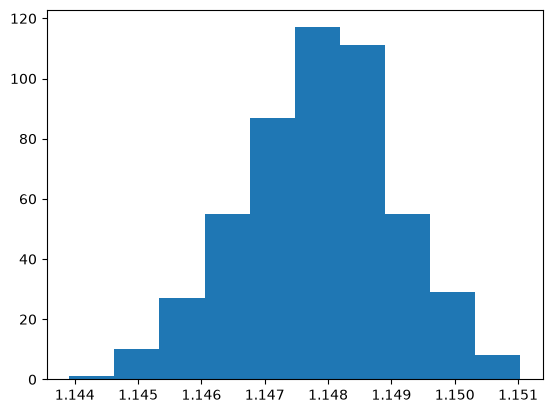

In [69]:
np.random.seed(29)
Theta_VA = np.zeros(m)
Cov = np.zeros(m)
for i in range(m):
    Theta_VA[i], Cov[i] = VA_unif(n)

plt.hist(Theta_VA)
plt.show()

In [72]:
var_teo_VA = var_teo_3 + np.mean(Cov)/n
var_empirico_VA = np.var(Theta_VA)

media_emp_VA = np.mean(Theta_VA)

print(f"Varianza teorica clasico = {var_teo_3}, Varainza empírica clasico = {var_empirico}, Varianza teorica VA = {var_teo_VA} y Varainza empírica clasico = {var_empirico_VA}")
print(f"Meida = {media_emp_3} y Meida = {media_emp_VA}")

Varianza teorica clasico = 1.59032432191788e-05, Varainza empírica clasico = 1.6000207953852027e-05, Varianza teorica VA = 1.3905987090250622e-06 y Varainza empírica clasico = 1.4374443472350845e-06
Meida = 1.1478956506329259 y Meida = 1.1478486215698385


np.float64(-0.08345344031980621)